# Audit daily volatility sources

Synthetic-only executable demonstration. No WRDS account, market observations or private files are used. Equal schema does not establish equal units or information. The audit reports findings and makes no repairs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from roughnoisy.compatibility import compare_daily
dates = pd.bdate_range('2014-01-02', periods=80).strftime('%Y-%m-%d')
reference = pd.DataFrame({'date': dates, 'symbol': 'SYNTHETIC', 'frequency_seconds': 60,
    'RV': .0001 * np.exp(.1*np.sin(np.arange(80))), 'RQ': 1e-8,
    'M_expected': 390, 'M_observed': 390})
candidate = reference.copy(deep=True)
candidate.loc[10, 'RV'] *= 10000
candidate.loc[10, 'RQ'] *= 100000000  # decimal-to-percent return-unit mismatch
candidate.loc[20, ['M_expected', 'M_observed']] = 210
candidate = candidate.drop(index=30)
candidate.loc[40, 'M_observed'] = 388
candidate.loc[40, ['RV', 'RQ']] = np.nan
candidate.loc[50, 'RV'] *= 8
candidate.loc[50, 'RQ'] *= 500
audit = compare_daily(reference, candidate)
expected = {10: 'material_difference', 20: 'session_count_disagreement',
            30: 'missing_candidate', 40: 'incomplete_grid', 50: 'material_difference'}
for index, status in expected.items():
    assert audit.set_index('date').loc[dates[index], 'status'] == status
findings = audit[audit.status.ne('no_material_difference')]
assert len(findings) == 5
assert audit.attrs['source_equivalence_certified'] is False
print('Passed planted checks: 5 findings; no repairs or equivalence certification.')

Passed planted checks: 5 findings; no repairs or equivalence certification.


In [2]:
findings[['date', 'status', 'RV_ratio', 'RQ_ratio']]

,date,status,RV_ratio,RQ_ratio
10,2014-01-16,material_difference,10000.0,100000000.0
20,2014-01-30,session_count_disagreement,NaN,NaN
30,2014-02-13,missing_candidate,NaN,NaN
40,2014-02-27,incomplete_grid,NaN,NaN
50,2014-03-13,material_difference,8.0,500.0


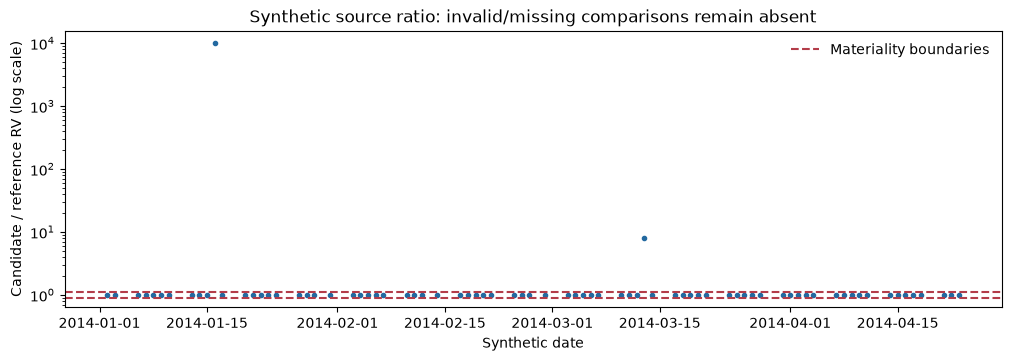

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.5), layout='constrained')
ax.semilogy(pd.to_datetime(audit.date), audit.RV_ratio, '.', color='#2369a0')
ax.axhline(1.1, color='#b33c49', linestyle='--', label='Materiality boundaries')
ax.axhline(1/1.1, color='#b33c49', linestyle='--')
ax.set(title='Synthetic source ratio: invalid/missing comparisons remain absent',
       ylabel='Candidate / reference RV (log scale)', xlabel='Synthetic date')
ax.legend(frameon=False)
plt.show()

## Interpret the findings

The tool flags a difference; it does not infer its cause. Missing rows or invalid grids are not agreements. You must verify common units, calendars, security mapping, sampling origin and data provenance. If both sources share a calendar error, a third calendar check is needed.

Before using the tool on real data: explain why percent-return units multiply RV by 10,000 and RQ by 100,000,000; predict how an early close changes M; explain why matching aggregates do not certify information equivalence. See docs/SOURCE_AUDIT.md and docs/OWNERSHIP_REVIEW.md.